# Paper figures

Variant A uses the interior photo pool. Variant B uses all photo types and all four CLIP features.
Both variants use the photo offer recorded in the source URLs for each property.

In [1]:
from pathlib import Path
import sys

working_dir = Path.cwd()
root = next(
    (path for path in (working_dir, *working_dir.parents) if (path / "inputs" / "prompts.json").is_file()),
    None,
)
if root is None:
    raise FileNotFoundError("Open this notebook from the final_project directory or one of its subdirectories.")
sys.path.insert(0, str(root / "code"))

In [2]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

from utils.paper_data import DATASETS_DIR, MARKETS, load_analysis_data
from utils.paper_plots import save_figure
from utils.paper_exhibits import FIGURE_TITLES, VARIANT_TITLES
from utils.paper_variants import listings_for_variant

inputs_dir = root / DATASETS_DIR
figure_assets = inputs_dir / "figure_assets"
figures_dir = root / "outputs" / "figures"
listings, photo_types, quality_models_by_type = load_analysis_data(root)

## Listing and photo descriptives

### Figure 2. Listing creation dates

Plot style from the original EDA notebook, cell 121.

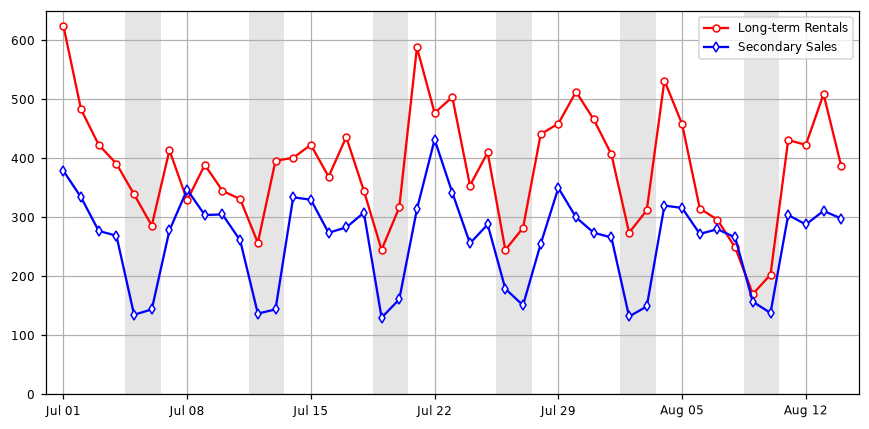

In [3]:
import matplotlib.dates as mdates

fig, ax = plt.subplots(figsize=(8, 4))
for (market, title), (marker, color) in zip(MARKETS.items(), [("o", "red"), ("d", "blue")]):
    dates = listings.loc[listings["deal_type"].eq(market), "date0"].dt.date
    counts = dates.value_counts().sort_index()
    ax.plot(counts.index, counts.values, label=title, marker=marker, color=color,
            markersize=4.5, markerfacecolor="white")

dates = pd.date_range(listings["date0"].min().normalize(), listings["date0"].max().normalize())
half_day = pd.Timedelta(hours=12)
for date in dates[dates.weekday >= 5]:
    ax.axvspan(date - half_day, date + half_day, color="grey", alpha=0.2, lw=0)

ax.set_xlim(dates[0] - 2 * half_day, dates[-1] + 2 * half_day)
ax.set_ylim(0, 650)
ax.set_xticks(dates[::7])
ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %d"))
ax.tick_params(labelsize=8)
ax.legend(fontsize=8)
ax.grid(True)
fig.tight_layout()
save_figure(fig, figures_dir, "02")

### Figure 3. Images per listing by author type

Plot style from the original EDA notebook, cell 123.

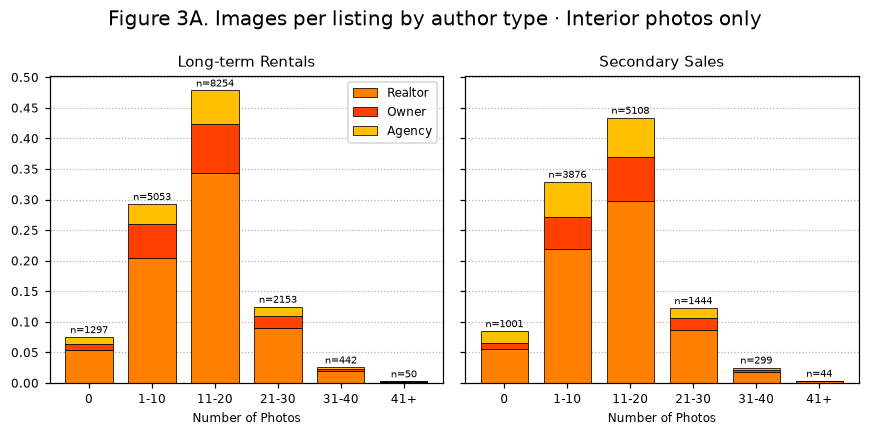

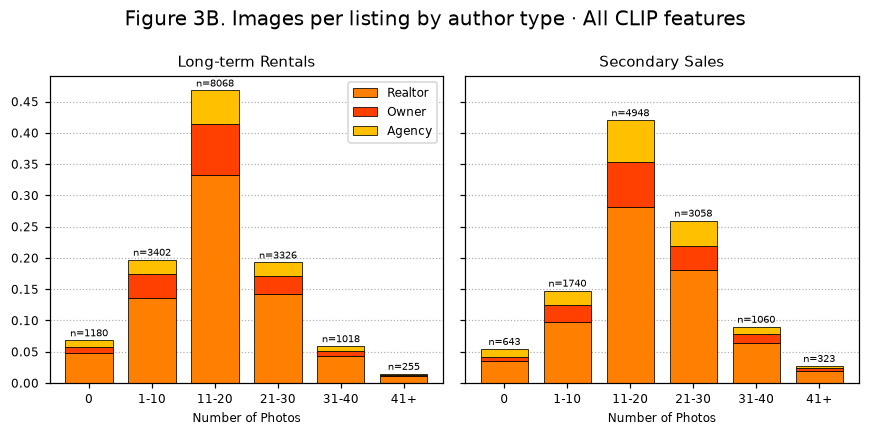

In [4]:
from matplotlib.ticker import MultipleLocator

from utils.paper_data import PHOTO_BINS

authors = ["Realtor", "Owner", "Agency"]
palette = sns.color_palette("autumn", n_colors=len(authors))
colors = [palette[1], palette[0], palette[2]]

for variant, label in VARIANT_TITLES.items():
    scoped = listings_for_variant(listings, variant)
    fig, axes = plt.subplots(1, 2, figsize=(8, 4), sharey=True)
    for ax, (market, title) in zip(axes, MARKETS.items()):
        data = scoped.loc[scoped["deal_type"].eq(market)]
        shares = pd.crosstab(data["link_num_categ"], data["author_cat"], normalize="all")
        shares = shares.reindex(index=PHOTO_BINS, columns=authors, fill_value=0)
        shares.plot(kind="bar", stacked=True, ax=ax, color=colors, width=0.75,
                    linewidth=0.5, edgecolor="black", legend=ax is axes[0])

        counts = data["link_num_categ"].value_counts().reindex(PHOTO_BINS, fill_value=0)
        for i, (height, count) in enumerate(zip(shares.sum(axis=1), counts)):
            ax.annotate(f"n={count}", (i, height), ha="center", va="bottom",
                        xytext=(0, 1), textcoords="offset points", fontsize=6.5)
        ax.set_title(title, fontsize=10)
        ax.set_xlabel("Number of Photos", fontsize=8)
        ax.tick_params(axis="x", rotation=0, labelsize=8)
        ax.tick_params(axis="y", labelsize=8)
        ax.yaxis.set_major_locator(MultipleLocator(0.05))
        ax.set_axisbelow(True)
        ax.grid(axis="y", linestyle=":")
    axes[0].legend(title="", fontsize=8)
    fig.suptitle(f"Figure 3{variant}. {FIGURE_TITLES['03']} · {label}", fontsize=13)
    fig.tight_layout()
    save_figure(fig, figures_dir, f"03_{variant}")

### Figure 4. Property location and number of images

Plot style from the original EDA notebook, cell 129.
The gray outlines use a 0.35 pt stroke to match the published rendering.

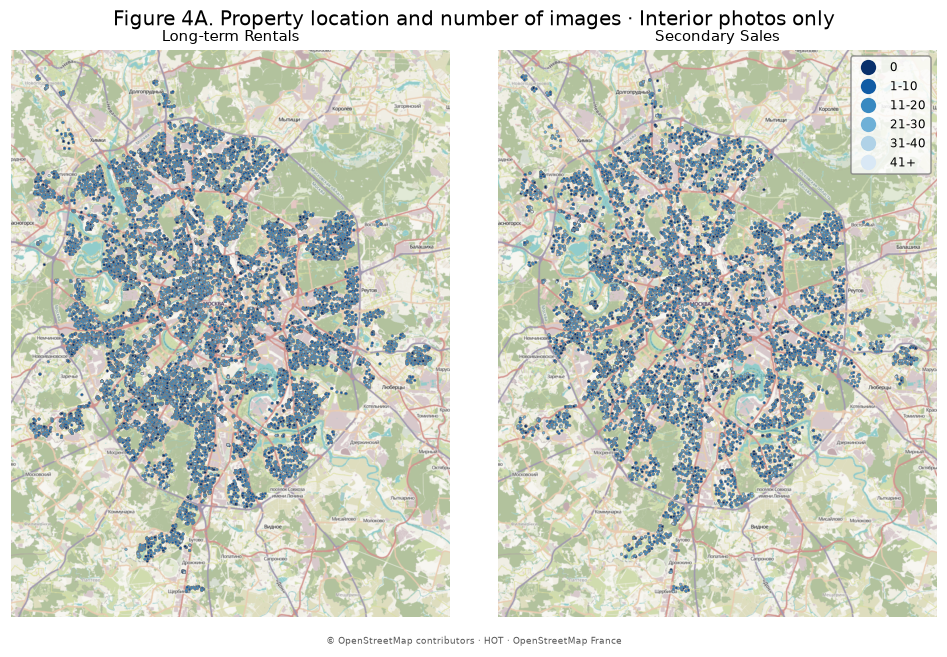

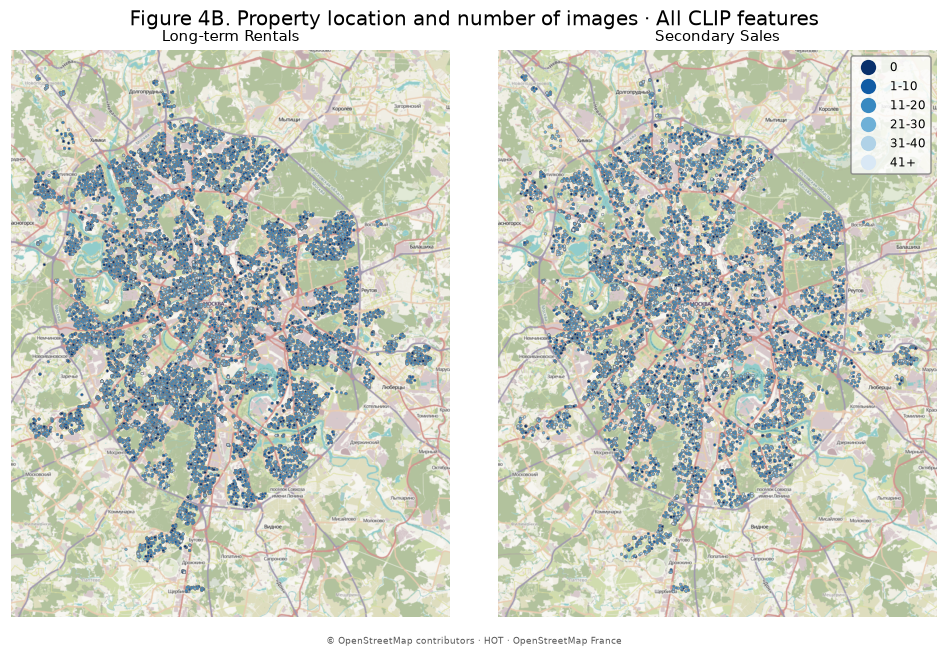

In [5]:
import geopandas as gpd
from matplotlib.colors import ListedColormap

from utils.paper_plots import add_basemap

points = gpd.GeoDataFrame(
    listings, geometry=gpd.points_from_xy(listings["lng"], listings["lat"]), crs=4326,
).to_crs(3857)
cmap = ListedColormap(plt.get_cmap("Blues_r")(np.linspace(0, 0.85, 256)))
missing = {"color": "lightgrey", "edgecolor": "red", "hatch": "///", "label": "Missing values"}

for variant, label in VARIANT_TITLES.items():
    scoped = listings_for_variant(points, variant)
    fig, axes = plt.subplots(1, 2, figsize=(9, 6))
    for ax, (market, title) in zip(axes, MARKETS.items()):
        data = scoped.loc[scoped["deal_type"].eq(market)]
        data.plot(column="link_num_categ", categorical=True, cmap=cmap, ax=ax,
                  markersize=3, linewidth=0.35, edgecolor="0.5", legend=ax is axes[1],
                  legend_kwds={"fontsize": 8, "edgecolor": "gray"},
                  missing_kwds=missing, rasterized=True)
        add_basemap(ax, figure_assets / "moscow_humanitarian.png")
        ax.set_title(title, fontsize=10)
        ax.set_axis_off()
    fig.suptitle(f"Figure 4{variant}. {FIGURE_TITLES['04']} · {label}", fontsize=13)
    fig.text(0.5, 0.02, "© OpenStreetMap contributors · HOT · OpenStreetMap France",
             ha="center", fontsize=6, color="0.35")
    fig.tight_layout(rect=(0, 0.035, 1, 1))
    save_figure(fig, figures_dir, f"04_{variant}", dpi=400)

## Score figures

Each score-dependent figure is exported once for A and once for B. The combined figures group the scores into panels on one page.

In [6]:
from utils.paper_variant_plots import export_variant_figures

export_variant_figures(figures_dir, inputs_dir, listings, photo_types, quality_models_by_type)

Saved Figures 05–17 and A1 for variant A
Saved Figures 05–17 and A1 for variant B
